# Stage 1 — single-particle tracking, MSD and direction correlation

**How to run**
1. Put the video under `videos/` and set `vid_filename` in the settings cell.
2. Run the settings, detector and preview cells. Check in the preview that exactly **one** circle
   (the intended object) is found; adjust `min_r`, `max_r` or `COLOR` if not.
3. Run the tracking cell (whole video, every frame).
4. **Inspect the MSD** (no fits yet): log–log MSD and its local slope α(t) for each segment.
5. **Set the ranges** at the top of the next cell (`RANGE_1`, `RANGE_2`, `RANGE_3`, lag seconds) and run it.
   Ranges 1 and 3 get a linear fit in log–log (power law `MSD ∝ lag^α`); **τ = middle of range 2**.
   To try other ranges, edit and re-run only that cell.
6. The direction-correlation section computes ⟨n(t′)·n(t′+t)⟩ and fits `y = a0 + a1·cos(a2·t)·exp(−a3·t)`.
7. The last cell compares the MSD with the MSD predicted from the correlation fit.

Plots are saved to `stage1_plots/`. Units: pixels and video seconds.

**Tracking rules** (from the stage-1 notes): multiple detections are filtered by a motion gate
(`300·Δt + 20` px from the last accepted centre); one survivor → its centre; several survivors that are
all pairwise ≤ 30 px apart → their mean; otherwise the frame is unresolved (NaN, never interpolated).
Frames where any surviving fitted circle crosses the image edge are excluded (NaN); excluded runs
longer than 3 s split the analysis into separate segments.

In [1]:
%matplotlib inline
from pathlib import Path
import math

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator
from scipy.optimize import curve_fit

# ---------------- video and detector ----------------
vid_filename = 'videos/2026-11-01_11-57-40.mp4'
min_r, max_r = 40, 60
COLOR = None                   # None (grayscale), 'green' or 'orange'
HSV_RANGE = {'green': ([35, 100, 100], [85, 255, 255]),     # (lower, upper) HSV bounds
             'orange': ([1, 175, 175], [20, 255, 255])}

# ---------------- tracking rules (provisional, pixels) ----------------
MAX_SPEED = 300.0              # px/s -> ~10 px per frame at 30 fps; not a physical bound
POSITION_MARGIN = 20.0         # px, allowance for fitted-centre jumps
MAX_CENTER_SEPARATION = 30.0   # px, all surviving candidates must be pairwise within this to average
MAX_OUTSIDE_RUN = 3.0          # s, longer clipped runs split the trajectory into segments

# ---------------- MSD ----------------
MSD_COMPONENT = 'xy'           # 'xy' (= <dx^2 + dy^2>, 2D), 'x' or 'y'
MSD_N_LAGS = 100               # log-spaced lags from 1 frame to MAX_LAG
MAX_LAG = 100                  # s, largest lag shown / used
FULL_INTERVAL_LAG_LIMIT = 20   # s, lags below this need every intermediate frame valid
MSD_LABEL = {'x': r"$\langle\Delta x^2\rangle$", 'y': r"$\langle\Delta y^2\rangle$",
             'xy': r"$\langle\Delta x^2+\Delta y^2\rangle$"}[MSD_COMPONENT] + r" (px$^2$)"

# ---------------- direction correlation ----------------
# Fit window for <n(t')n(t'+t)>. Lag 0 is 1 by construction and the first 1-2 frame lags are
# dominated by tracking jitter (anticorrelation), so they are left out. Beyond ~20-30 s the curve
# keeps oscillating without damping and a single damped cosine no longer describes it.
CORR_FIT_RANGE = (0.1, 20.0)   # s

PLOT_DIR = Path('stage1_plots')
PLOT_DIR.mkdir(exist_ok=True)

## Circle detection (from `single_basics`)

In [2]:
def find_circles(frame):
    # Returns the detected circles as rows (x, y, r); empty if none.
    if COLOR:
        lower, upper = (np.array(b) for b in HSV_RANGE[COLOR])
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV), lower, upper)
        edges = cv2.Canny(cv2.GaussianBlur(mask, (9, 9), 2), 50, 150)
        circles = cv2.HoughCircles(edges, cv2.HOUGH_GRADIENT, dp=1.2, minDist=15,
                                   param1=50, param2=20, minRadius=min_r, maxRadius=max_r)
    else:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)
        circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, 1, minDist=21,
                                   param1=50, param2=30, minRadius=min_r, maxRadius=max_r)
    return np.empty((0, 3)) if circles is None else circles[0]

## Preview: check the detector on the first frames

3610 frames, 30.000 fps, 1920x1080 px
frame 0: x=1024.5, y=403.5, r=44.0
frame 1: x=1024.5, y=403.5, r=44.0
frame 2: x=1023.5, y=404.5, r=42.7


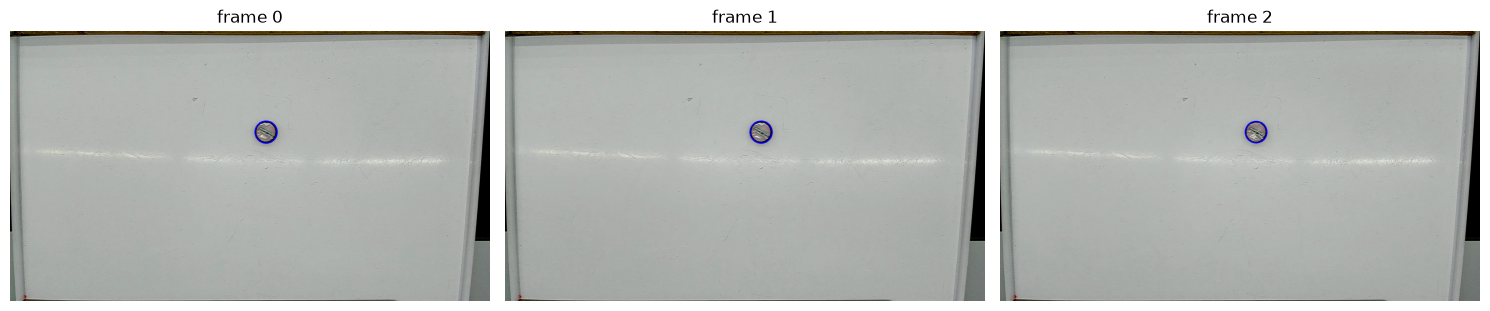

In [3]:
N_PREVIEW = 3
cap = cv2.VideoCapture(vid_filename)
if not cap.isOpened():
    raise RuntimeError(f"Cannot open {vid_filename}")
print(f"{int(cap.get(cv2.CAP_PROP_FRAME_COUNT))} frames, {cap.get(cv2.CAP_PROP_FPS):.3f} fps, "
      f"{int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))}x{int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))} px")

fig, axes = plt.subplots(1, N_PREVIEW, figsize=(5 * N_PREVIEW, 3.2))
for i, ax in enumerate(np.atleast_1d(axes)):
    ret, frame = cap.read()
    if not ret:
        break
    found = find_circles(frame)
    if len(found) != 1:
        print(f"WARNING: frame {i}: {len(found)} circles detected - check the detector settings.")
    for x, y, r in found:
        cv2.circle(frame, (int(round(x)), int(round(y))), int(round(r)), (255, 0, 0), 4)
        print(f"frame {i}: x={x:.1f}, y={y:.1f}, r={r:.1f}")
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {i}")
    ax.axis('off')
cap.release()
plt.tight_layout()
plt.show()

## Tracking the whole video

In [4]:
def select_center(candidates, previous_center, elapsed_time):
    # Return (selected centre or None, candidates passing the motion gate).
    candidates = list(candidates)
    if len(candidates) > 1 and previous_center is not None:
        limit = MAX_SPEED * elapsed_time + POSITION_MARGIN
        candidates = [c for c in candidates if math.dist(c[:2], previous_center) <= limit]
    count = len(candidates)
    if count == 1:
        return tuple(float(v) for v in candidates[0][:2]), candidates
    if count == 0 or previous_center is None:
        return None, candidates
    # Every pair must be close: a chain of nearby centres is not enough.
    if any(math.dist(a[:2], b[:2]) > MAX_CENTER_SEPARATION
           for i, a in enumerate(candidates) for b in candidates[i + 1:]):
        return None, candidates
    return tuple(math.fsum(float(c[k]) for c in candidates) / count for k in (0, 1)), candidates


def circle_outside(circle, width, height):
    x, y, r = map(float, circle[:3])
    return x - r < 0 or x + r > width - 1 or y - r < 0 or y + r > height - 1


def split_segments(t, xy, outside):
    # Split at clipped runs longer than MAX_OUTSIDE_RUN; shorter runs stay as NaN gaps.
    segments, segment_start, runs, long_runs, i = [], 0, 0, 0, 0
    while i < len(t):
        if not outside[i]:
            i += 1
            continue
        start = i
        while i < len(t) and outside[i]:
            i += 1
        end_time = t[i] if i < len(t) else t[-1]   # at EOF: lower bound
        duration = end_time - t[start]
        runs += 1
        if duration > MAX_OUTSIDE_RUN:
            long_runs += 1
            print(f"SEGMENT BREAK: outside run frames {start}-{i - 1}, {duration:.2f} s")
            if segment_start < start:
                segments.append((t[segment_start:start], xy[segment_start:start]))
            segment_start = i
    if segment_start < len(t):
        segments.append((t[segment_start:], xy[segment_start:]))
    print(f"Outside frames: {int(np.sum(outside))}; outside runs: {runs}; "
          f"runs > {MAX_OUTSIDE_RUN:g} s: {long_runs}")
    usable = []
    for times, pos in segments:
        if np.isfinite(pos).all(axis=1).sum() >= 2:
            usable.append((times, pos))
        else:
            print("Segment omitted: fewer than two valid positions.")
    return usable


def track_video(video_filename, verbose=False):
    # Detect the circle in every frame. Returns a list of segments (t [s], xy [px, shape (N, 2)]).
    cap = cv2.VideoCapture(str(video_filename))
    if not cap.isOpened():
        raise RuntimeError("Cannot open the selected video.")
    n_reported = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    t, xy, outside = [], [], []
    previous_center = previous_time = None
    multiple = averaged = motion_resolved = rejected = unresolved = 0
    try:
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            time = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000
            if t and time <= t[-1]:
                raise RuntimeError("Video timestamps must be strictly increasing.")
            candidates = find_circles(frame)
            elapsed = None if previous_time is None else time - previous_time
            center, surviving = select_center(candidates, previous_center, elapsed)
            height, width = frame.shape[:2]
            clipped = any(circle_outside(c, width, height) for c in surviving)
            idx = len(t)
            if len(candidates) > 1:
                multiple += 1
                rejected += len(candidates) - len(surviving)
                if center is not None and not clipped:
                    if len(surviving) == 1:
                        motion_resolved += 1
                    else:
                        averaged += 1
                if verbose:
                    print(f"frame {idx}: {len(candidates)} circles, {len(surviving)} pass gate, "
                          f"averaged={center is not None and len(surviving) > 1 and not clipped}")
            t.append(time)
            outside.append(clipped)
            if clipped:
                xy.append((np.nan, np.nan))
            elif center is None:
                unresolved += 1
                xy.append((np.nan, np.nan))
                if verbose:
                    print(f"UNRESOLVED: frame {idx}, t={time:.3f} s")
            else:
                xy.append(center)
                previous_center, previous_time = center, time
            if idx % 500 == 0:
                print(f"  processed {idx}/{n_reported} frames", end="\r")
    finally:
        cap.release()
    if n_reported > 0 and len(t) != n_reported:
        print(f"WARNING: decoded {len(t)} frames but the video reports {n_reported}.")
    print(f"\nFrames: {len(t)}; multi-detection: {multiple} (motion-resolved {motion_resolved}, "
          f"averaged {averaged}); rejected candidates: {rejected}; unresolved: {unresolved}")
    if unresolved:
        print(f"{unresolved} unresolved frames kept as NaN (not interpolated).")
    return split_segments(np.array(t), np.array(xy, dtype=float), np.array(outside))

  processed 3500/3610 frames
Frames: 3610; multi-detection: 561 (motion-resolved 50, averaged 425); rejected candidates: 56; unresolved: 0
Outside frames: 116; outside runs: 13; runs > 3 s: 0
2026-11-01_11-57-40_segment_01: 0.00-120.30 s, 3494/3610 valid positions


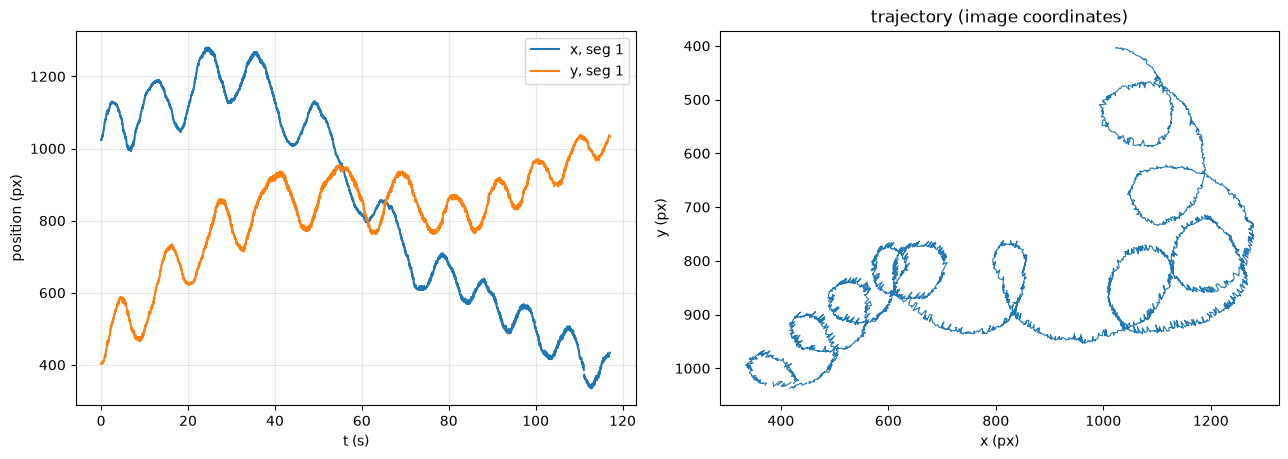

In [5]:
video_stem = Path(vid_filename).stem
segments = {f"{video_stem}_segment_{n:02d}": segment
            for n, segment in enumerate(track_video(vid_filename), start=1)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for n, (name, (t_seg, xy_seg)) in enumerate(segments.items(), start=1):
    ax1.plot(t_seg, xy_seg[:, 0], label=f"x, seg {n}")
    ax1.plot(t_seg, xy_seg[:, 1], label=f"y, seg {n}")
    ax2.plot(xy_seg[:, 0], xy_seg[:, 1], lw=0.8)
    print(f"{name}: {t_seg[0]:.2f}-{t_seg[-1]:.2f} s, "
          f"{np.isfinite(xy_seg).all(axis=1).sum()}/{len(t_seg)} valid positions")
ax1.set_xlabel("t (s)"); ax1.set_ylabel("position (px)"); ax1.legend(); ax1.grid(alpha=0.3)
ax2.set_xlabel("x (px)"); ax2.set_ylabel("y (px)"); ax2.invert_yaxis(); ax2.set_aspect('equal')
ax2.set_title("trajectory (image coordinates)")
fig.tight_layout()
fig.savefig(PLOT_DIR / f"{video_stem}_trajectory.png", dpi=150)
plt.show()

## MSD: inspect first, then fit ranges

**Step 1 – inspect.** Time-averaged MSD on log-spaced lags (1 frame up to `MAX_LAG`) for every segment, with its local slope
α(t) = d log MSD / d log t underneath (α ≈ 2 ballistic, ≈ 1 diffusive, ≈ 0 plateau). The plot opens in a
separate window: **hover to read lag, MSD and slope**. Both axes are logarithmic because the ranges are fitted
as power laws (straight lines in log–log); set `INSPECT_LOG_X = False` for a linear lag axis.

Lags are whole numbers of frames, log-spaced so every decade of lag gets similar resolution. The shortest lags (≲ 0.2 s) sit on the
localisation-noise floor (slope < 1); don't put a range there. Only pairs with valid endpoints are used; for lags below
`FULL_INTERVAL_LAG_LIMIT` every frame in between must also be valid. Pairs never cross segments.
Each fit is unweighted least squares of `log10(MSD)` vs `log10(lag)`, i.e. `MSD = 10^b · lag^α`.
τ is the arithmetic midpoint of range 2.

In [6]:
def calculate_msd(t, xy, component=MSD_COMPONENT, n_lags=MSD_N_LAGS):
    # Time-averaged MSD on log-spaced frame lags (1 frame ... MAX_LAG).
    # Returns two arrays: mean actual lag [s] and MSD [px^2] (both empty if the segment is too short).
    t = np.asarray(t, float)
    xy = np.asarray(xy, float)
    cols = {'x': [0], 'y': [1], 'xy': [0, 1]}[component]
    dt = float(np.median(np.diff(t)))
    max_k = min(len(t) - 1, int(round(MAX_LAG / dt)))
    if max_k < 1:
        return np.array([]), np.array([])
    ks = np.unique(np.round(np.logspace(0, np.log10(max_k), n_lags)).astype(int))
    valid = np.isfinite(xy).all(axis=1)
    excluded = np.concatenate([[0], np.cumsum(~valid)])   # for the full-interval rule
    lags, msd = [], []
    for k in ks:
        i = np.arange(len(t) - k)
        j = i + k
        keep = valid[i] & valid[j]
        if k * dt < FULL_INTERVAL_LAG_LIMIT:
            keep &= excluded[j + 1] == excluded[i]       # every frame in between valid
        if not keep.any():
            continue
        d = xy[j[keep]][:, cols] - xy[i[keep]][:, cols]
        lags.append((t[j[keep]] - t[i[keep]]).mean())
        msd.append(np.mean(np.sum(d ** 2, axis=1)))
    return np.array(lags), np.array(msd)


def fit_power_law(lag, msd, rng):
    sel = (lag >= rng[0]) & (lag <= rng[1])
    if sel.sum() < 3:
        raise ValueError(f"Need at least 3 lag points in range {rng} s (have {sel.sum()}).")
    alpha, b = np.polyfit(np.log10(lag[sel]), np.log10(msd[sel]), 1)
    return alpha, b, sel


def msd_range_fit(lag, msd, name, ranges):
    # Fit ranges 1 and 3 (log-log), tau = middle of range 2. Returns a results dict.
    r1, r2, r3 = ranges
    if not (0 < r1[0] < r1[1] <= r2[0] < r2[1] <= r3[0] < r3[1]):
        raise ValueError(f"{name}: ranges must be increasing and non-overlapping: {r1}, {r2}, {r3}")
    if r3[1] > lag[-1]:
        raise ValueError(f"{name}: RANGE_3 ends at {r3[1]} s but the largest lag is {lag[-1]:g} s.")
    a1, b1, s1 = fit_power_law(lag, msd, r1)
    a3, b3, s3 = fit_power_law(lag, msd, r3)
    tau = 0.5 * (r2[0] + r2[1])

    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.loglog(lag, msd, 'o', ms=4, color='tab:blue', label='MSD data')
    colors = ('tab:orange', 'tab:gray', 'tab:green')
    for k, (rng, c) in enumerate(zip(ranges, colors), start=1):
        ax.axvspan(*rng, color=c, alpha=0.12, label=f"range {k}: {rng[0]:g}-{rng[1]:g} s")
    for alpha, b, sel, c, k in ((a1, b1, s1, colors[0], 1), (a3, b3, s3, colors[2], 3)):
        xx = np.logspace(np.log10(lag[sel][0]), np.log10(lag[sel][-1]), 50)
        ax.loglog(xx, 10 ** b * xx ** alpha, '--', lw=2.2, color=c,
                  label=rf"fit {k}: $\alpha$={alpha:.2f}")
    ax.axvline(tau, color='tab:purple', ls=':', lw=1.5, label=rf"$\tau$ = {tau:g} s (mid range 2)")
    ax.set_xlabel("lag time (s)")
    ax.set_ylabel(MSD_LABEL)
    ax.set_title(name)
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{name}_msd.png", dpi=200)
    plt.show()

    print(f"{name}")
    print(f"  Range 1 {r1}: alpha = {a1:.3f}, prefactor 10^b = {10 ** b1:.4g} px^2/s^alpha, {s1.sum()} lags")
    print(f"  Range 3 {r3}: alpha = {a3:.3f}, prefactor 10^b = {10 ** b3:.4g} px^2/s^alpha, {s3.sum()} lags")
    print(f"  tau (middle of range 2 {r2}) = {tau:g} s")
    return dict(alpha_1=a1, b_1=b1, alpha_3=a3, b_3=b3, tau=tau, ranges=ranges)

In [7]:
%matplotlib tk
# Step 1: compute and inspect the MSD of every segment (no ranges, no fits).
# The plot opens in its own window (interactive backend); hover to read lag, MSD and local slope.
# If tk does not work for you, use `%matplotlib qt`, or `%matplotlib widget` (needs `pip install ipympl`).
INSPECT_LOG_X = True   # True: log-log (power laws are straight lines). False: linear lag axis.


def inspect_msd(lag, msd, name, log_x=INSPECT_LOG_X):
    slope = np.gradient(np.log10(msd), np.log10(lag))   # local alpha = dlog MSD / dlog lag

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7.5), sharex=True,
                                   gridspec_kw=dict(height_ratios=[2, 1]))
    ax1.plot(lag, msd, 'o-', ms=3.5, lw=0.8)
    ax1.set_yscale('log')
    ax2.plot(lag, slope, '.-', ms=4, lw=0.8)
    for ref, txt in ((0, 'plateau'), (1, 'diffusive'), (2, 'ballistic')):
        ax2.axhline(ref, color='gray', lw=0.8, ls='--')
        ax2.text(1.005, ref, txt, transform=ax2.get_yaxis_transform(), fontsize=8,
                 color='gray', va='center')
    ax2.set_ylim(-0.5, 2.5)
    if log_x:
        ax2.set_xscale('log')
        ax2.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
        ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))   # 1, 2, 5, 10, ...
        ax2.xaxis.set_minor_formatter(plt.NullFormatter())
    ax1.set_ylabel(MSD_LABEL)
    ax2.set_ylabel(r"local slope $\alpha$")
    ax2.set_xlabel("lag time (s)")
    ax1.set_title(f"{name}: MSD for choosing ranges (hover for values)")
    for ax in (ax1, ax2):
        ax.grid(True, which='both', alpha=0.3)

    # ---- hover: nearest lag point, shown in both panels ----
    vlines = [ax.axvline(lag[0], color='tab:red', lw=0.8, visible=False) for ax in (ax1, ax2)]
    marker, = ax1.plot([], [], 'o', ms=8, mfc='none', mec='tab:red', mew=1.5)
    annot = ax1.annotate("", xy=(0, 0), xytext=(12, -12), textcoords="offset points",
                         va='top', fontsize=9, visible=False,
                         bbox=dict(boxstyle="round", fc="white", ec="tab:red", alpha=0.9))

    def on_move(event):
        if event.inaxes not in (ax1, ax2) or event.xdata is None:
            if annot.get_visible():
                annot.set_visible(False)
                marker.set_data([], [])
                for v in vlines:
                    v.set_visible(False)
                fig.canvas.draw_idle()
            return
        x = event.xdata
        i = int(np.argmin(np.abs(np.log(lag) - np.log(x)) if (log_x and x > 0) else np.abs(lag - x)))
        annot.xy = (lag[i], msd[i])
        # keep the box inside the plot: flip it to the left of the point in the right half
        right_half = ax1.transAxes.inverted().transform(ax1.transData.transform((lag[i], msd[i])))[0] > 0.6
        annot.set_position((-12, -12) if right_half else (12, -12))
        annot.set_ha('right' if right_half else 'left')
        annot.set_text(f"lag = {lag[i]:g} s\nMSD = {msd[i]:.4g} px$^2$\nslope = {slope[i]:.2f}")
        annot.set_visible(True)
        marker.set_data([lag[i]], [msd[i]])
        for v in vlines:
            v.set_xdata([lag[i], lag[i]])
            v.set_visible(True)
        fig.canvas.draw_idle()

    fig.canvas.mpl_connect('motion_notify_event', on_move)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{name}_msd_inspect.png", dpi=150)
    plt.show()
    print(f"{name}: lags {lag[0]:.3g}-{lag[-1]:.3g} s, {len(lag)} points")
    return fig


if 'inline' in plt.get_backend().lower():
    print("Note: inline backend - plots are static, hover will not work.")

msd_data = {}   # name -> (lag, msd)
for name, (t_seg, xy_seg) in segments.items():
    lag, msd = calculate_msd(t_seg, xy_seg)
    if len(lag) == 0:
        print(f"{name}: no MSD (segment too short)")
        continue
    msd_data[name] = (lag, msd)
    inspect_msd(lag, msd, name)

2026-11-01_11-57-40_segment_01: lags 0.0333-100 s, 80 points


**Step 2 – set the ranges** from the plots above and run the cell. Edit and re-run only this cell to try
other ranges. With several segments, the same ranges are used for all of them.

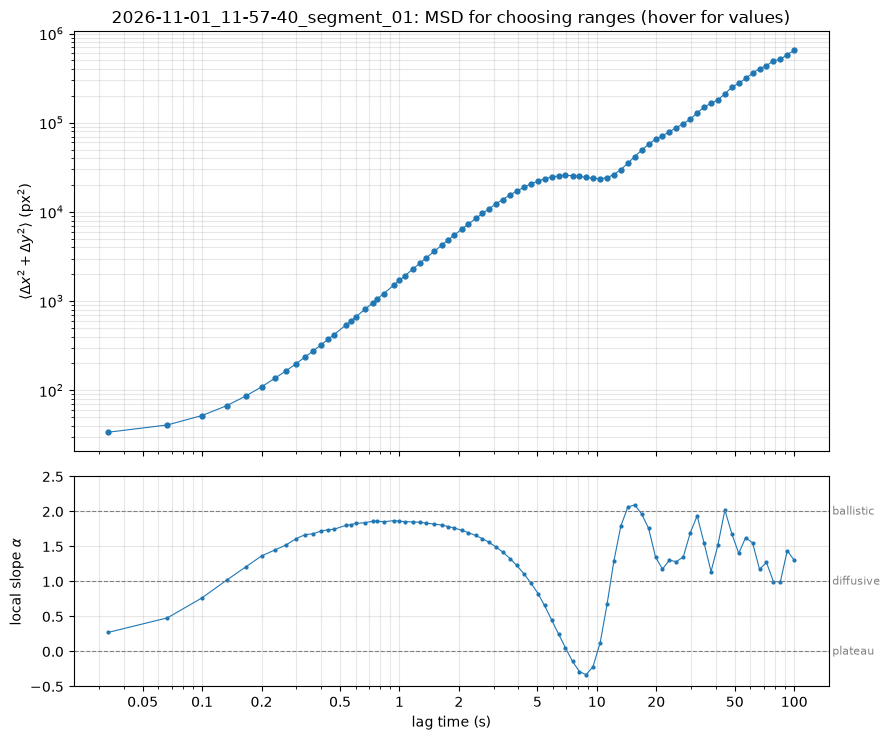

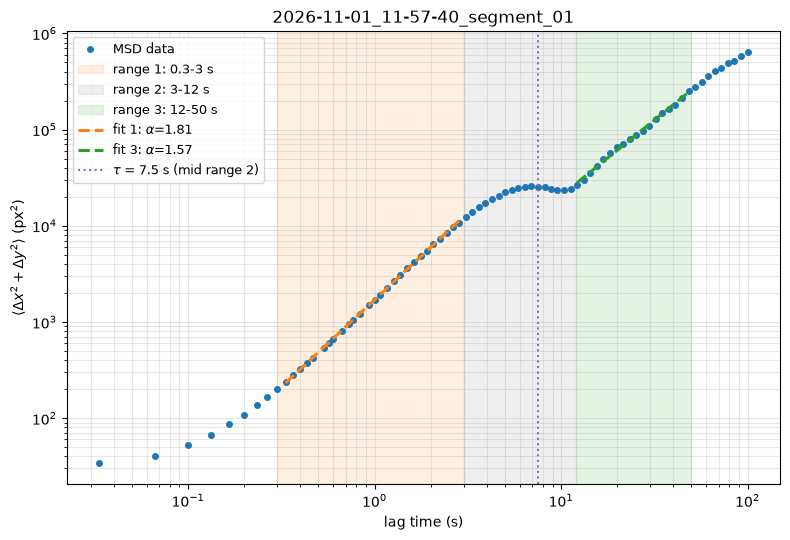

2026-11-01_11-57-40_segment_01
  Range 1 (0.3, 3): alpha = 1.813, prefactor 10^b = 1699 px^2/s^alpha, 27 lags
  Range 3 (12, 50): alpha = 1.573, prefactor 10^b = 549 px^2/s^alpha, 18 lags
  tau (middle of range 2 (3, 12)) = 7.5 s


In [8]:
%matplotlib inline
RANGE_1 = (0.3, 3)   # s  -> linear fit in log-log
RANGE_2 = (3, 12)    # s  -> tau = middle of this range
RANGE_3 = (12, 50)   # s  -> linear fit in log-log

msd_results = {name: msd_range_fit(lag, msd, name, (RANGE_1, RANGE_2, RANGE_3))
               for name, (lag, msd) in msd_data.items()}

## Velocity-direction correlation ⟨n(t′)·n(t′+t)⟩ and fit

`n_i` is the unit vector of the displacement between consecutive frames (zero steps and steps touching
a NaN are skipped, slots kept). For each frame offset the dot products are averaged; the lag is the
mean actual midpoint separation. The curve is then fitted with
$y = a_0 + a_1\cos(a_2 t)\,e^{-a_3 t}$ (unweighted least squares on the `CORR_FIT_RANGE` window, several starting points, best kept).
The dotted red line extends the fitted curve outside the window.

In [9]:
def calculate_direction_correlation(t, xy, max_lag=MAX_LAG):
    # Returns two arrays: mean actual lag [s] and C, one entry per frame offset.
    times = np.asarray(t, float)
    pos = np.asarray(xy, float)
    dt = np.diff(times)
    disp = np.diff(pos, axis=0)
    dist = np.hypot(disp[:, 0], disp[:, 1])
    valid = np.isfinite(disp).all(axis=1) & (dist > 0)
    n = np.full_like(disp, np.nan)
    n[valid] = disp[valid] / dist[valid, None]
    mid = times[:-1] + dt / 2
    print(f"valid directions: {valid.sum()}/{len(valid)}; zero steps: {np.count_nonzero(dist == 0)}")
    lag_out, C_out = [], []
    for k in range(len(n)):
        lags = mid[k:] - mid[:len(n) - k]
        if lags.min() > max_lag:
            break
        keep = valid[:len(n) - k] & valid[k:] & (lags <= max_lag)
        if not keep.any():
            continue
        dots = np.sum(n[:len(n) - k][keep] * n[k:][keep], axis=1)
        lag_out.append(lags[keep].mean())
        C_out.append(dots.mean())
    return np.array(lag_out), np.array(C_out)


def corr_model(x, a0, a1, a2, a3):
    return a0 + a1 * np.cos(a2 * x) * np.exp(-a3 * x)


def fit_direction_correlation(lag, C, fit_range=CORR_FIT_RANGE):
    sel = (lag >= fit_range[0]) & (lag <= fit_range[1])
    x, y = lag[sel], C[sel]
    a0_guess = float(np.mean(y[x > 0.5 * x.max()]))
    # dominant frequency of the curve as one of the starting guesses for a2
    yy = y - a0_guess
    freqs = np.fft.rfftfreq(len(yy), d=np.median(np.diff(x)))
    f_peak = freqs[1:][np.argmax(np.abs(np.fft.rfft(yy))[1:])]
    a2_guesses = {2 * np.pi * f_peak, 0.0, 0.05, 0.2, 0.6, 2.0}
    best = None
    for a2 in a2_guesses:
        for a3 in (0.01, 0.1, 0.5, 2.0):
            p0 = [a0_guess, 1 - a0_guess, a2, a3]
            try:
                p, cov = curve_fit(corr_model, x, y, p0=p0,
                                   bounds=([-1, -2, 0, 0], [1, 2, np.inf, np.inf]), maxfev=20000)
            except (RuntimeError, ValueError):
                continue
            sse = float(np.sum((y - corr_model(x, *p)) ** 2))
            if best is None or sse < best[0]:
                best = (sse, p, cov)
    if best is None:
        raise RuntimeError("Correlation fit did not converge from any starting point.")
    sse, p, cov = best
    r2 = 1 - sse / float(np.sum((y - y.mean()) ** 2))
    return p, np.sqrt(np.diag(cov)), r2, sel


def direction_correlation_analysis(t, xy, name):
    lag, C = calculate_direction_correlation(t, xy)
    if len(lag) == 0:
        print("No valid directions; no correlation plot.")
        return None
    p, perr, r2, sel = fit_direction_correlation(lag, C)

    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.plot(lag, C, '-', lw=0.8, color='tab:blue', label='data')
    lo, hi = lag[sel].min(), lag[sel].max()
    ax.axvspan(lo, hi, color='tab:red', alpha=0.06, label=f"fit window {lo:.2g}-{hi:.3g} s")
    xx = np.linspace(0, MAX_LAG, 4000)
    ax.plot(xx, corr_model(xx, *p), ':', lw=1.2, color='tab:red')   # extrapolation
    xx = np.linspace(lo, hi, 2000)
    ax.plot(xx, corr_model(xx, *p), '-', lw=2, color='tab:red',
            label=(r"fit $a_0+a_1\cos(a_2t)e^{-a_3t}$" + "\n"
                   + rf"$a_0$={p[0]:.3g}, $a_1$={p[1]:.3g}" + "\n"
                   + rf"$a_2$={p[2]:.3g} s$^{{-1}}$, $a_3$={p[3]:.3g} s$^{{-1}}$"
                   + "\n" + rf"$R^2$={r2:.3f}"))
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xlim(0, MAX_LAG)
    ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel("lag time t (s)")
    ax.set_ylabel(r"$\langle \mathbf{n}(t')\cdot\mathbf{n}(t'+t)\rangle_{t'}$")
    ax.set_title(name)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{name}_direction_correlation.png", dpi=200)
    plt.show()

    for k, (v, e) in enumerate(zip(p, perr)):
        print(f"a{k} = {v:.5g} +/- {e:.2g}")
    if p[2] > 0:
        print(f"oscillation period 2*pi/a2 = {2 * np.pi / p[2]:.3g} s")
    if p[3] > 0:
        print(f"decay time 1/a3 = {1 / p[3]:.3g} s")
    print(f"R^2 = {r2:.4f} over {sel.sum()} lag points. Errors assume independent points; "
          "overlapping pairs are correlated, so they are underestimates.")
    return dict(params=p, errors=perr, r2=r2)

===== 2026-11-01_11-57-40_segment_01 =====
valid directions: 3385/3609; zero steps: 96


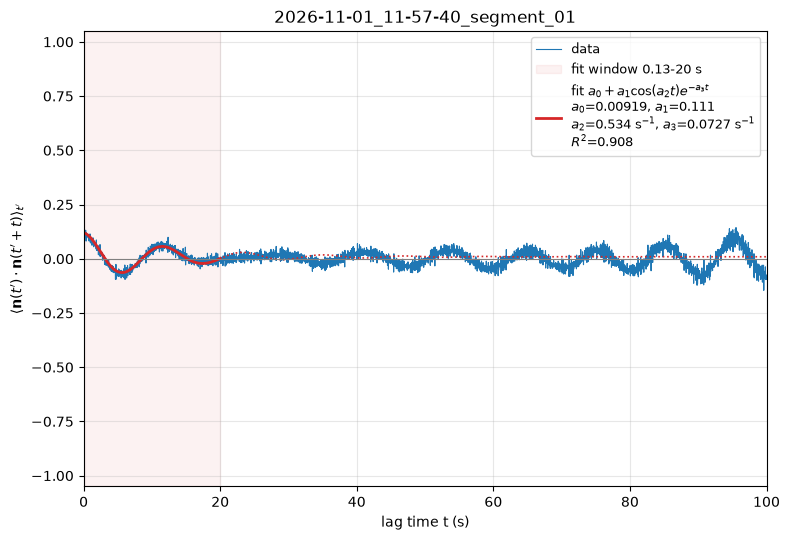

a0 = 0.0091926 +/- 0.0006
a1 = 0.11073 +/- 0.0022
a2 = 0.53393 +/- 0.0018
a3 = 0.072688 +/- 0.0027
oscillation period 2*pi/a2 = 11.8 s
decay time 1/a3 = 13.8 s
R^2 = 0.9084 over 597 lag points. Errors assume independent points; overlapping pairs are correlated, so they are underestimates.


In [10]:
corr_results = {}
for name, (t_seg, xy_seg) in segments.items():
    print(f"===== {name} =====")
    corr_results[name] = direction_correlation_analysis(t_seg, xy_seg, name)

## MSD vs the MSD predicted from the direction-correlation fit

Correlation fit:      a2 = 0.534 1/s, a3 = 0.073 1/s (period 11.77 s, 1/a3 = 13.76 s)
A) a2, a3 fixed:      v = 44.5 px/s, c = 1.11e-13 px^2, rms log-residual = 0.450
B) all free:          a2 = 0.608 +/- 0.077 1/s, a3 = 0.262 +/- 0.055 1/s (1/a3 = 3.82 s), v = 44.8 px/s, c = 1.58e-15 px^2, rms log-residual = 0.191
Errors assume independent lag points; overlapping pairs make them underestimates.


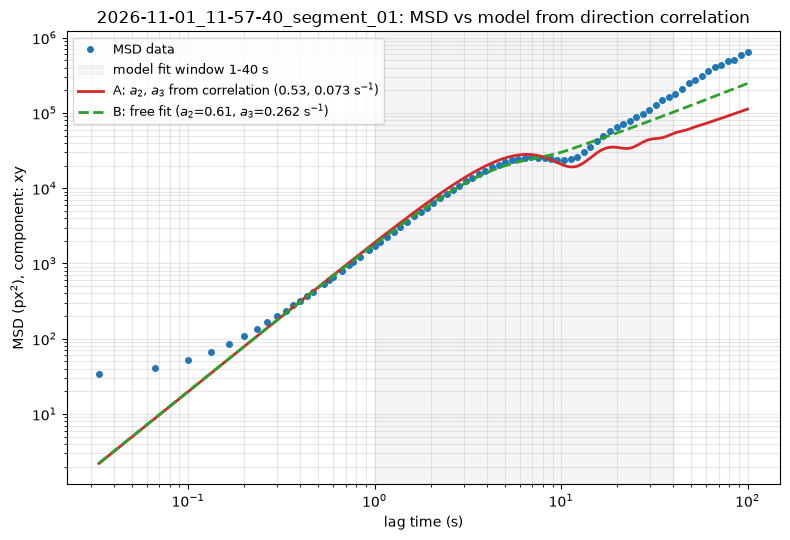

In [11]:
# ===== Like-with-like: MSD predicted from the direction-correlation model =====
# Model: the velocity correlation has the same shape as the fitted direction correlation,
#   <v(t')·v(t'+s)> = v^2 cos(a2 s) exp(-a3 s)        (constant speed v, a chiral/circling swimmer)
# Integrating it twice gives the MSD per component (x or y) in closed form, with lam = a3 - i*a2:
#   MSD_x(t) = v^2 * Re[ t/lam - (1 - exp(-lam t))/lam^2 ] + c
# c is a constant offset (localisation noise, 2*sigma^2). Long-time limit: slope 1 with
# D_x = v^2 a3 / (2 (a2^2 + a3^2)). The model has no drift, walls or field-of-view limit.
#
# Two fits, both on log(MSD) over MSD_MODEL_FIT_RANGE:
#   A) prediction test: a2, a3 fixed from the correlation fit; only v^2 and c are free
#   B) free fit: v^2, a2, a3, c all free; compare a2, a3 with the correlation fit

MSD_MODEL_FIT_RANGE = (1, 40)   # s; stop before the field-of-view plateau (~40-70 s here)


def chiral_msd(t, v2, a2, a3, c, component=MSD_COMPONENT):
    lam = a3 - 1j * a2
    t = np.asarray(t, float)
    one_axis = v2 * np.real(t / lam - (1 - np.exp(-lam * t)) / lam ** 2)
    return (2 if component == 'xy' else 1) * one_axis + c


def compare_msd_with_correlation(lag, msd, corr_params, name, fit_range=MSD_MODEL_FIT_RANGE):
    _, _, a2_c, a3_c = corr_params
    if a2_c <= 0 or a3_c <= 0:
        print(f"{name}: correlation fit gave a2 = {a2_c:.3g}, a3 = {a3_c:.3g}; "
              "the model needs both > 0, comparison skipped.")
        return None
    sel = (lag >= fit_range[0]) & (lag <= fit_range[1])
    x, y = lag[sel], msd[sel]
    log_resid = lambda f: np.log(f) - np.log(y)

    # A) a2, a3 fixed from the correlation fit
    def model_a(t, log_v2, c):
        return chiral_msd(t, np.exp(log_v2), a2_c, a3_c, c)
    pA, _ = curve_fit(model_a, x, y, p0=[np.log(y[-1] / x[-1] * 2 * a3_c), 0.0],
                      bounds=([-np.inf, 0], [np.inf, np.inf]),
                      sigma=y, maxfev=20000)        # sigma=y ~ relative (log-like) errors
    fA = model_a(x, *pA)

    # B) everything free; several starting points, best kept
    best = None
    for a2_0 in (a2_c, 0.3 * a2_c, 3 * a2_c, 0.05):
        for a3_0 in (a3_c, 0.3 * a3_c, 3 * a3_c, 0.05):
            p0 = [pA[0], a2_0, a3_0, pA[1]]
            try:
                p, cov = curve_fit(lambda t, lv2, a2, a3, c: chiral_msd(t, np.exp(lv2), a2, a3, c),
                                   x, y, p0=p0, sigma=y, maxfev=20000,
                                   bounds=([-np.inf, 0, 1e-6, 0], [np.inf, np.inf, np.inf, np.inf]))
            except (RuntimeError, ValueError):
                continue
            f = chiral_msd(x, np.exp(p[0]), *p[1:])
            sse = float(np.sum(log_resid(f) ** 2))
            if best is None or sse < best[0]:
                best = (sse, p, cov)
    if best is None:
        raise RuntimeError("Free MSD-model fit did not converge.")
    _, pB, covB = best
    errB = np.sqrt(np.diag(covB))
    fB = chiral_msd(x, np.exp(pB[0]), *pB[1:])

    rms = lambda f: float(np.sqrt(np.mean(log_resid(f) ** 2)))
    print(f"Correlation fit:      a2 = {a2_c:.3f} 1/s, a3 = {a3_c:.3f} 1/s "
          f"(period {2 * np.pi / a2_c:.2f} s, 1/a3 = {1 / a3_c:.2f} s)")
    print(f"A) a2, a3 fixed:      v = {np.sqrt(np.exp(pA[0])):.1f} px/s, c = {pA[1]:.3g} px^2, "
          f"rms log-residual = {rms(fA):.3f}")
    print(f"B) all free:          a2 = {pB[1]:.3f} +/- {errB[1]:.2g} 1/s, "
          f"a3 = {pB[2]:.3f} +/- {errB[2]:.2g} 1/s (1/a3 = {1 / pB[2]:.2f} s), "
          f"v = {np.sqrt(np.exp(pB[0])):.1f} px/s, c = {pB[3]:.3g} px^2, "
          f"rms log-residual = {rms(fB):.3f}")
    print("Errors assume independent lag points; overlapping pairs make them underestimates.")

    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.loglog(lag, msd, 'o', ms=4, color='tab:blue', label='MSD data')
    ax.axvspan(*fit_range, color='gray', alpha=0.08, label=f"model fit window {fit_range[0]:g}-{fit_range[1]:g} s")
    tt = np.logspace(np.log10(lag[0]), np.log10(lag[-1]), 400)
    ax.loglog(tt, model_a(tt, *pA), '-', lw=2, color='tab:red',
              label=rf"A: $a_2$, $a_3$ from correlation ({a2_c:.2f}, {a3_c:.3f} s$^{{-1}}$)")
    ax.loglog(tt, chiral_msd(tt, np.exp(pB[0]), *pB[1:]), '--', lw=2, color='tab:green',
              label=rf"B: free fit ($a_2$={pB[1]:.2f}, $a_3$={pB[2]:.3f} s$^{{-1}}$)")
    ax.set_xlabel("lag time (s)")
    ax.set_ylabel("MSD (px$^2$), component: " + MSD_COMPONENT)
    ax.set_title(name + ": MSD vs model from direction correlation")
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{name}_msd_vs_correlation_model.png", dpi=200)
    plt.show()
    return dict(fixed=pA, free=pB, free_errors=errB)


comparisons = {name: compare_msd_with_correlation(lag, msd, corr_results[name]['params'], name)
               for name, (lag, msd) in msd_data.items() if corr_results.get(name) is not None}

## τ from the MSD vs τ from the direction correlation

τ_MSD is the middle of the MSD transition range (`RANGE_2`); τ_corr = 1/a3 is the decay time of the
direction-correlation fit. The range-2 interval is shown as a rough uncertainty for τ_MSD; the error on
τ_corr comes from the fit (δτ = δa3 / a3²) and is an underestimate.

In [12]:
print(f"{'segment':<34}{'tau_MSD (s)':>14}{'range 2 (s)':>14}{'tau_corr = 1/a3 (s)':>24}{'ratio':>8}")
for name, msd_res in msd_results.items():
    corr_res = corr_results.get(name)
    if corr_res is None or corr_res['params'][3] <= 0:
        print(f"{name:<34}{msd_res['tau']:>14.3g}   (no usable correlation fit)")
        continue
    a3, a3_err = corr_res['params'][3], corr_res['errors'][3]
    tau_msd, tau_corr = msd_res['tau'], 1 / a3
    r2 = msd_res['ranges'][1]
    print(f"{name:<34}{tau_msd:>14.3g}{f'{r2[0]:g}-{r2[1]:g}':>14}"
          f"{f'{tau_corr:.3g} +/- {a3_err / a3 ** 2:.2g}':>24}{tau_msd / tau_corr:>8.2f}")

segment                              tau_MSD (s)   range 2 (s)     tau_corr = 1/a3 (s)   ratio
2026-11-01_11-57-40_segment_01               7.5          3-12           13.8 +/- 0.51    0.55
